<a href="https://colab.research.google.com/github/Sanhith30/ITA0330-Mobile-Computing/blob/main/Lab_Exp/MC_exp_16_to_21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXPERIMENT 16: Free-Space Path Loss and Received Power

Frequency = 900 MHz
  d (km)   FSPL (dB)   Pr (dBm)        Pr (W)
     0.1       71.52     -13.52     4.441e-05
     0.5       85.50     -27.50     1.777e-06
     1.0       91.52     -33.52     4.441e-07
     2.0       97.55     -39.55     1.110e-07
     5.0      105.50     -47.50     1.777e-08
    10.0      111.52     -53.52     4.441e-09

Frequency = 1800 MHz
  d (km)   FSPL (dB)   Pr (dBm)        Pr (W)
     0.1       77.55     -19.55     1.110e-05
     0.5       91.52     -33.52     4.441e-07
     1.0       97.55     -39.55     1.110e-07
     2.0      103.57     -45.57     2.776e-08
     5.0      111.52     -53.52     4.441e-09
    10.0      117.55     -59.55     1.110e-09


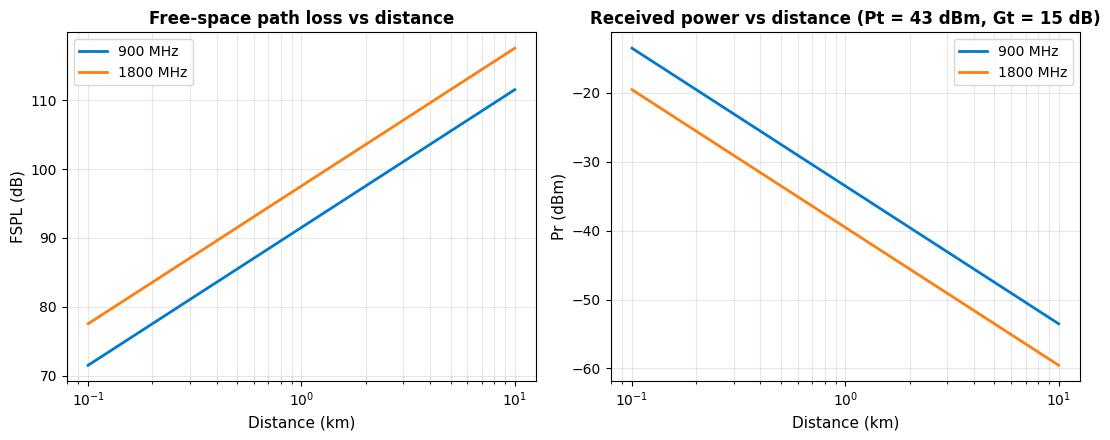


[Saved Graph]: plots/Figure_16_1_FSPL_and_Received_Power.png


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs('plots', exist_ok=True)

def fspl_db(d_km, f_mhz):
    """Free-space path loss in dB (d in km, f in MHz)."""
    return 20 * np.log10(d_km) + 20 * np.log10(f_mhz) + 32.44

Pt_dbm, Gt_db, Gr_db = 43.0, 15.0, 0.0 # BS power, BS gain, MS gain
distances = [0.1, 0.5, 1, 2, 5, 10] # km

print("=" * 60)
print("EXPERIMENT 16: Free-Space Path Loss and Received Power")
print("=" * 60)

for f in (900, 1800):
    print(f"\nFrequency = {f} MHz")
    print(f"{'d (km)':>8}{'FSPL (dB)':>12}{'Pr (dBm)':>11}{'Pr (W)':>14}")
    for d in distances:
        L = fspl_db(d, f)
        Pr = Pt_dbm + Gt_db + Gr_db - L
        Pr_w = 10**(Pr / 10) / 1000
        print(f"{d:8.1f}{L:12.2f}{Pr:11.2f}{Pr_w:14.3e}")

# High-resolution plot matching Figure 16.1 in manual
d_fine = np.logspace(-1, 1, 200) # 0.1 to 10 km
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Subplot 1: FSPL vs Distance
ax1.plot(d_fine, fspl_db(d_fine, 900), label='900 MHz', color='#007acc', lw=2)
ax1.plot(d_fine, fspl_db(d_fine, 1800), label='1800 MHz', color='#ff7f0e', lw=2)
ax1.set_xscale('log')
ax1.set_xlabel('Distance (km)', fontsize=11)
ax1.set_ylabel('FSPL (dB)', fontsize=11)
ax1.set_title('Free-space path loss vs distance', fontsize=12, fontweight='bold')
ax1.grid(True, which="both", ls="-", alpha=0.3)
ax1.legend(fontsize=10)

# Subplot 2: Received Power vs Distance
Pr_900 = Pt_dbm + Gt_db + Gr_db - fspl_db(d_fine, 900)
Pr_1800 = Pt_dbm + Gt_db + Gr_db - fspl_db(d_fine, 1800)
ax2.plot(d_fine, Pr_900, label='900 MHz', color='#007acc', lw=2)
ax2.plot(d_fine, Pr_1800, label='1800 MHz', color='#ff7f0e', lw=2)
ax2.set_xscale('log')
ax2.set_xlabel('Distance (km)', fontsize=11)
ax2.set_ylabel('Pr (dBm)', fontsize=11)
ax2.set_title('Received power vs distance (Pt = 43 dBm, Gt = 15 dB)', fontsize=12, fontweight='bold')
ax2.grid(True, which="both", ls="-", alpha=0.3)
ax2.legend(fontsize=10)

plt.tight_layout()
plot_path = os.path.join('plots', 'Figure_16_1_FSPL_and_Received_Power.png')
plt.savefig(plot_path, dpi=300)
plt.show() # Display the plot directly here
print(f"\n[Saved Graph]: {plot_path}")

EXPERIMENT 17: Frequency (Co-channel) Reuse: Cluster Size, Capacity and S/I
  N     D/R  ch/cell  Capacity C  S/I (dB)
  1   1.732      420        4200      1.76
  3   3.000      140        4200     11.30
  4   3.464      105        4200     13.80
  7   4.583       60        4200     18.66
  9   5.196       46        4140     20.85
 12   6.000       35        4200     23.34
 13   6.245       32        4160     24.04
 16   6.928       26        4160     25.84

Smallest cluster size meeting S/I >= 18.0 dB : N = 7


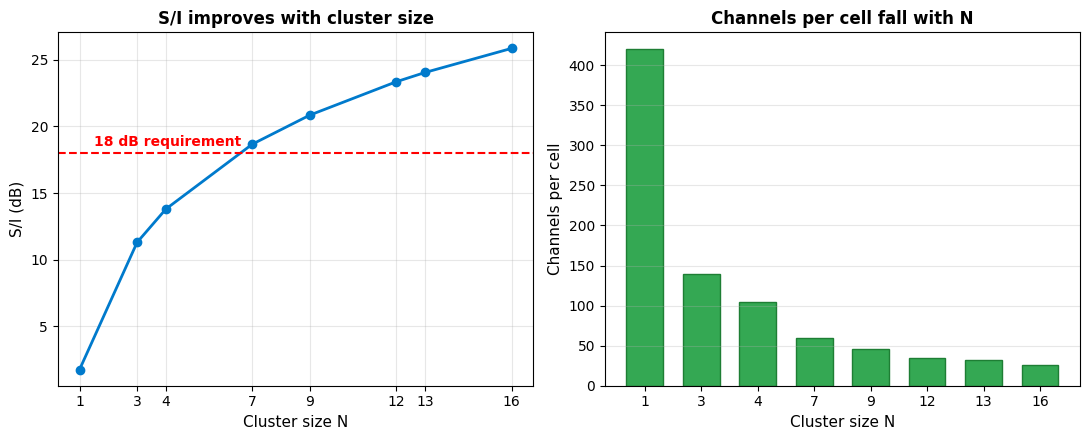


[Saved Graph]: plots/Figure_17_2_SI_and_Channels_vs_ClusterSize.png


In [7]:
import math
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs('plots', exist_ok=True)

S = 420 # total duplex channels available
M = 10 # number of times the cluster is replicated
n = 4 # path-loss exponent (urban)
valid = sorted({i*i + i*j + j*j for i in range(0, 5) for j in range(0, 5)} - {0})[:8]

print("=" * 60)
print("EXPERIMENT 17: Frequency (Co-channel) Reuse: Cluster Size, Capacity and S/I")
print("=" * 60)

print(f"{'N':>3}{'D/R':>8}{'ch/cell':>9}{'Capacity C':>12}{'S/I (dB)':>10}")
si_list = []
ch_list = []
for N in valid:
    Q = math.sqrt(3*N) # co-channel reuse ratio D/R
    k = S // N # channels per cell
    C = M * k * N # system capacity = M*k*N
    si = (Q**n) / 6 # 6 first-tier interferers
    si_db = 10*math.log10(si)
    si_list.append(si_db)
    ch_list.append(k)
    print(f"{N:>3}{Q:8.3f}{k:9d}{C:12d}{si_db:10.2f}")

req = 18.0 # AMPS requirement (dB)
for N in valid:
    if 10*math.log10((math.sqrt(3*N)**n)/6) >= req:
        print(f"\nSmallest cluster size meeting S/I >= {req} dB : N = {N}")
        break

# High-resolution plot matching Figure 17.2 in manual
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Subplot 1: S/I vs Cluster Size N
ax1.plot(valid, si_list, marker='o', color='#007acc', lw=2, markersize=6)
ax1.axhline(18, color='red', linestyle='--', label='18 dB requirement')
ax1.text(1.5, 18.5, '18 dB requirement', color='red', fontsize=10, fontweight='bold')
ax1.set_xlabel('Cluster size N', fontsize=11)
ax1.set_ylabel('S/I (dB)', fontsize=11)
ax1.set_title('S/I improves with cluster size', fontsize=12, fontweight='bold')
ax1.set_xticks(valid)
ax1.grid(True, alpha=0.3)

# Subplot 2: Channels per cell fall with N
ax2.bar([str(v) for v in valid], ch_list, color='#34a853', width=0.65, edgecolor='#1e7e34')
ax2.set_xlabel('Cluster size N', fontsize=11)
ax2.set_ylabel('Channels per cell', fontsize=11)
ax2.set_title('Channels per cell fall with N', fontsize=12, fontweight='bold')
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plot_path = os.path.join('plots', 'Figure_17_2_SI_and_Channels_vs_ClusterSize.png')
plt.savefig(plot_path, dpi=300)
plt.show()
print(f"\n[Saved Graph]: {plot_path}")

EXPERIMENT 18: Call Blocking Probability Using the Erlang B Formula
Blocking probability (%)
E \ m         5       10       15       20       25       30
    2     3.670    0.004    0.000    0.000    0.000    0.000
    5    28.487    1.838    0.016    0.000    0.000    0.000
   10    56.395   21.458    3.650    0.187    0.003    0.000
   20    76.436   53.796   33.000   15.889    5.022    0.846

For E = 10 Erlangs and GoS = 2% -> channels required = 17


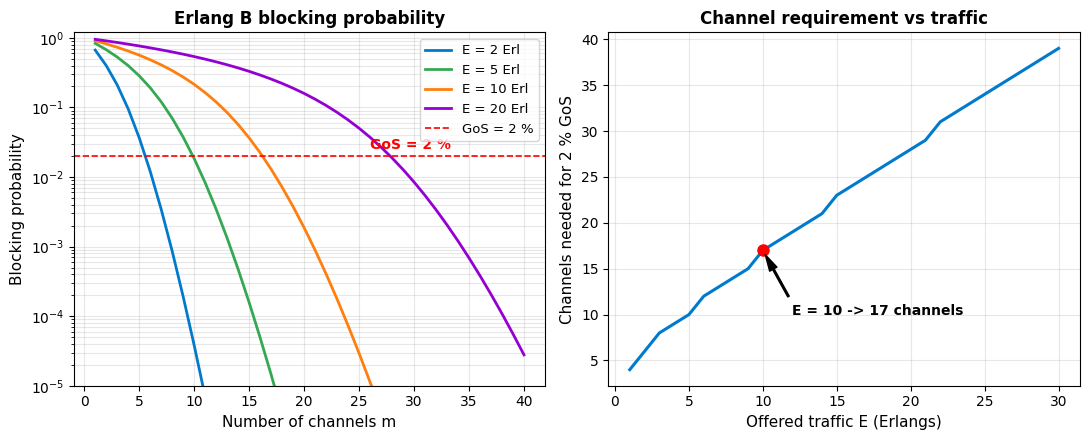


[Saved Graph]: plots/Figure_18_1_Erlang_B_Blocking_and_Capacity.png


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs('plots', exist_ok=True)

def erlang_b(E, m):
    """Blocking probability using the recursive Erlang-B formula."""
    B = 1.0
    for k in range(1, m + 1):
        B = (E * B) / (k + E * B)
    return B

loads = [2, 5, 10, 20]
channels = [5, 10, 15, 20, 25, 30]

print("=" * 60)
print("EXPERIMENT 18: Call Blocking Probability Using the Erlang B Formula")
print("=" * 60)

print("Blocking probability (%)")
print("E \\ m " + "".join(f"{m:>9}" for m in channels))
for E in loads:
    print(f"{E:>5} " + "".join(f"{100*erlang_b(E, m):9.3f}" for m in channels))

E_target, target_gos = 10, 0.02
m_target = 1
while erlang_b(E_target, m_target) > target_gos:
    m_target += 1
print(f"\nFor E = {E_target} Erlangs and GoS = {target_gos*100:.0f}% -> channels required = {m_target}")

# High-resolution plot matching Figure 18.1 in manual
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Subplot 1: Erlang B blocking probability vs number of channels
m_range = np.arange(1, 41)
colors = {2: '#007acc', 5: '#34a853', 10: '#ff7f0e', 20: '#9400d3'}
for E_val in loads:
    b_vals = [erlang_b(E_val, c) for c in m_range]
    ax1.plot(m_range, b_vals, label=f'E = {E_val} Erl', color=colors[E_val], lw=2)

ax1.axhline(0.02, color='red', linestyle='--', label='GoS = 2 %', lw=1.2)
ax1.text(26, 0.025, 'GoS = 2 %', color='red', fontsize=10, fontweight='bold')
ax1.set_yscale('log')
ax1.set_ylim(1e-5, 1.2)
ax1.set_xlabel('Number of channels m', fontsize=11)
ax1.set_ylabel('Blocking probability', fontsize=11)
ax1.set_title('Erlang B blocking probability', fontsize=12, fontweight='bold')
ax1.grid(True, which="both", alpha=0.3)
ax1.legend(loc='upper right', fontsize=9.5)

# Subplot 2: Channels needed for 2% GoS vs offered traffic E
E_vals = np.arange(1, 31)
m_reqs = []
for e in E_vals:
    ch = 1
    while erlang_b(e, ch) > 0.02:
        ch += 1
    m_reqs.append(ch)

ax2.plot(E_vals, m_reqs, color='#007acc', lw=2.2)
ax2.plot(10, 17, 'ro', markersize=8)
ax2.annotate('E = 10 -> 17 channels', xy=(10, 17), xytext=(12, 10),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1.2, headwidth=6),
             fontsize=10, fontweight='bold')
ax2.set_xlabel('Offered traffic E (Erlangs)', fontsize=11)
ax2.set_ylabel('Channels needed for 2 % GoS', fontsize=11)
ax2.set_title('Channel requirement vs traffic', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plot_path = os.path.join('plots', 'Figure_18_1_Erlang_B_Blocking_and_Capacity.png')
plt.savefig(plot_path, dpi=300)
plt.show()
print(f"\n[Saved Graph]: {plot_path}")

EXPERIMENT 19: Handoff Simulation with Hysteresis
 H (dB)  Handoffs  Ping-pongs
      0        35          34
      2        27          26
      4        11          10
      6         7           6
      8         3           2
     10         1           0

Handoff events with H = 6 dB (position in metres): [(1010.0, '1->2'), (1015.0, '2->1'), (1045.0, '1->2'), (1060.0, '2->1'), (1070.0, '1->2'), (1095.0, '2->1'), (1105.0, '1->2')]


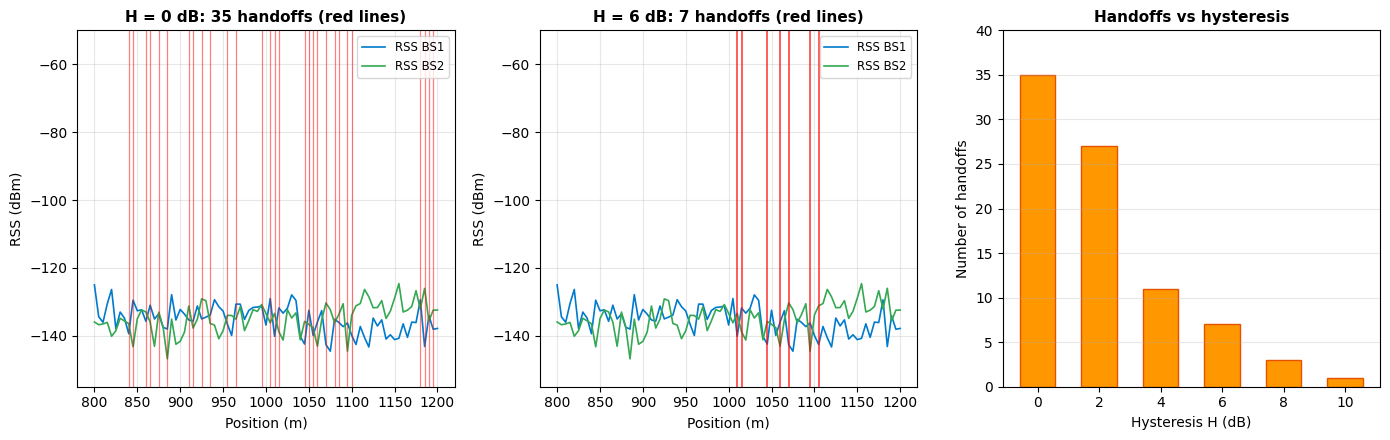


[Saved Graph]: plots/Figure_19_1_Handoff_Simulation_with_Hysteresis.png


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs('plots', exist_ok=True)

rng = np.random.default_rng(7)
D = 2000.0 # BS1 at x=0, BS2 at x=D (metres)
P0, n, sigma = -30.0, 3.5, 4.0 # dBm at 1 m, path-loss exponent, shadowing sd (dB)
x = np.arange(10, D, 5.0) # mobile moves from BS1 to BS2

def rss(d, shadow):
    return P0 - 10*n*np.log10(d) + shadow

r1 = rss(x, rng.normal(0, sigma, x.size))
r2 = rss(D - x, rng.normal(0, sigma, x.size))

def run(H):
    serving, handoffs, log = 1, 0, []
    for xi, a, b in zip(x, r1, r2):
        if serving == 1 and b > a + H:
            serving, handoffs = 2, handoffs + 1
            log.append((float(xi), '1->2'))
        elif serving == 2 and a > b + H:
            serving, handoffs = 1, handoffs + 1
            log.append((float(xi), '2->1'))
    return handoffs, log

print("=" * 60)
print("EXPERIMENT 19: Handoff Simulation with Hysteresis")
print("=" * 60)

print(f"{'H (dB)':>7}{'Handoffs':>10}{'Ping-pongs':>12}")
h_counts = []
for H in (0, 2, 4, 6, 8, 10):
    h, log = run(H)
    h_counts.append(h)
    print(f"{H:7d}{h:10d}{max(h-1, 0):12d}")

h6, log6 = run(6)
print("\nHandoff events with H = 6 dB (position in metres):", log6)

# High-resolution plot matching Figure 19.1 in manual
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.5))

mask = (x >= 800) & (x <= 1200)

# Subplot 1: H = 0 dB
h0, log0 = run(0)
ax1.plot(x[mask], r1[mask], label='RSS BS1', color='#007acc', lw=1.2)
ax1.plot(x[mask], r2[mask], label='RSS BS2', color='#34a853', lw=1.2)
for pos, _ in log0:
    if 800 <= pos <= 1200:
        ax1.axvline(pos, color='red', alpha=0.5, lw=0.9)
ax1.set_title(f'H = 0 dB: {h0} handoffs (red lines)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Position (m)', fontsize=10)
ax1.set_ylabel('RSS (dBm)', fontsize=10)
ax1.set_ylim(-155, -50)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper right', fontsize=8.5)

# Subplot 2: H = 6 dB
ax2.plot(x[mask], r1[mask], label='RSS BS1', color='#007acc', lw=1.2)
ax2.plot(x[mask], r2[mask], label='RSS BS2', color='#34a853', lw=1.2)
for pos, _ in log6:
    if 800 <= pos <= 1200:
        ax2.axvline(pos, color='red', alpha=0.75, lw=1.2)
ax2.set_title(f'H = 6 dB: {h6} handoffs (red lines)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Position (m)', fontsize=10)
ax2.set_ylabel('RSS (dBm)', fontsize=10)
ax2.set_ylim(-155, -50)
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper right', fontsize=8.5)

# Subplot 3: Handoffs vs Hysteresis
ax3.bar([str(H) for H in (0, 2, 4, 6, 8, 10)], h_counts, color='#ff9800', width=0.58, edgecolor='#e65100')
ax3.set_title('Handoffs vs hysteresis', fontsize=11, fontweight='bold')
ax3.set_xlabel('Hysteresis H (dB)', fontsize=10)
ax3.set_ylabel('Number of handoffs', fontsize=10)
ax3.set_ylim(0, 40)
ax3.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plot_path = os.path.join('plots', 'Figure_19_1_Handoff_Simulation_with_Hysteresis.png')
plt.savefig(plot_path, dpi=300)
plt.show()
print(f"\n[Saved Graph]: {plot_path}")

EXPERIMENT 20: Code Division Multiple Access (CDMA): Spreading and Despreading
User 1 data : [1, 0, 1, 1]
User 1 spread : [ 1 -1  1 -1 -1  1 -1  1  1 -1  1 -1  1 -1  1 -1]
User 2 data : [0, 0, 1, 0]
User 2 spread : [-1 -1  1  1 -1 -1  1  1  1  1 -1 -1 -1 -1  1  1]
User 3 data : [1, 1, 0, 1]
User 3 spread : [ 1 -1 -1  1  1 -1 -1  1 -1  1  1 -1  1 -1 -1  1]

Composite transmitted signal:
 [ 1 -3  1  1 -1 -1 -1  3  1  1  1 -3  1 -3  1  1]

Despreading at receiver:
User 1 correlator: [ 1. -1.  1.  1.] -> bits [1, 0, 1, 1] OK
User 2 correlator: [-1. -1.  1. -1.] -> bits [0, 0, 1, 0] OK
User 3 correlator: [ 1.  1. -1.  1.] -> bits [1, 1, 0, 1] OK


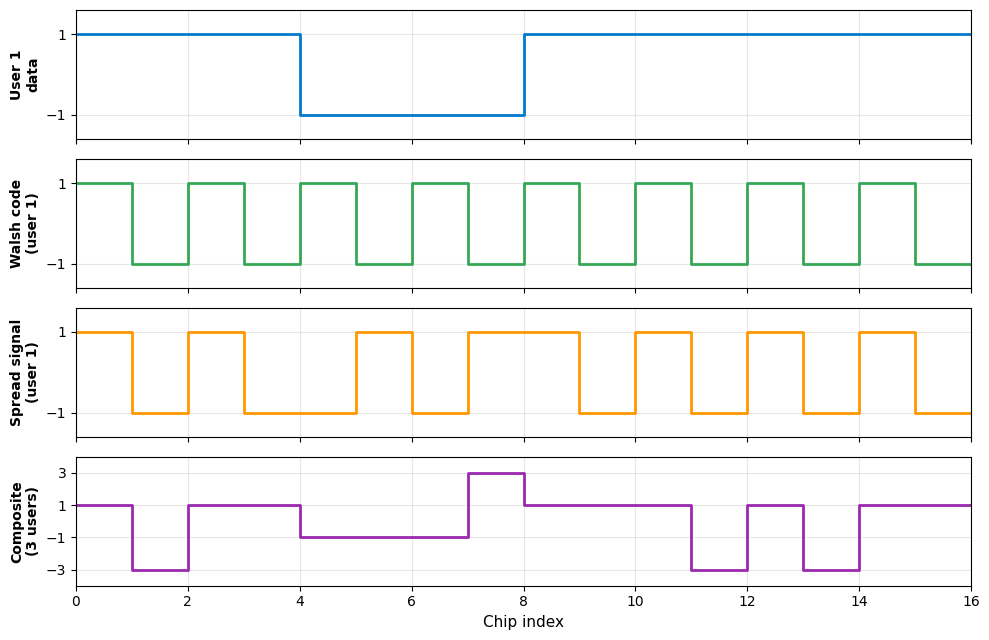


[Saved Graph 1]: plots/Figure_20_1_CDMA_Waveforms.png


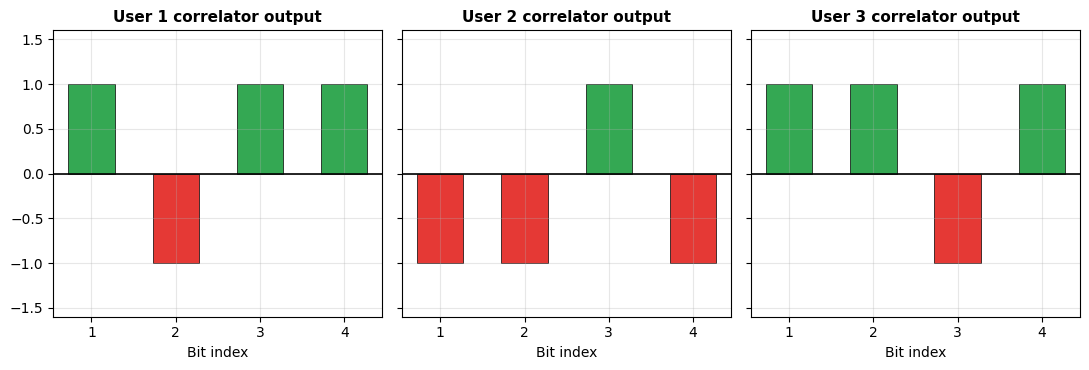

[Saved Graph 2]: plots/Figure_20_2_CDMA_Correlator_Outputs.png


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs('plots', exist_ok=True)

# Orthogonal Walsh codes of length 4 (rows of Hadamard matrix)
W = np.array([[ 1,  1,  1,  1],
              [ 1, -1,  1, -1],
              [ 1,  1, -1, -1],
              [ 1, -1, -1,  1]])

bits = {1: [1, 0, 1, 1], 2: [0, 0, 1, 0], 3: [1, 1, 0, 1]} # three users
L = W.shape[1]
nbits = 4

def bpsk(b):
    return 2*np.array(b) - 1

print("=" * 60)
print("EXPERIMENT 20: Code Division Multiple Access (CDMA): Spreading and Despreading")
print("=" * 60)

tx = np.zeros(nbits*L)
user_spreads = {}
for u, b in bits.items():
    spread = np.repeat(bpsk(b), L) * np.tile(W[u], nbits)
    user_spreads[u] = spread
    print(f"User {u} data : {b}")
    print(f"User {u} spread : {spread.astype(int)}")
    tx += spread

print("\nComposite transmitted signal:\n", tx.astype(int))

print("\nDespreading at receiver:")
correlator_outputs = {}
for u, b in bits.items():
    corr = (tx * np.tile(W[u], nbits)).reshape(nbits, L).sum(axis=1) / L
    correlator_outputs[u] = corr
    rec = (corr > 0).astype(int)
    print(f"User {u} correlator: {corr} -> bits {rec.tolist()} "
          f"{'OK' if rec.tolist()==b else 'ERROR'}")

# Figure 20.1: Waveforms (Data, Walsh code, Spread signal, Composite signal)
fig1, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(10, 6.5), sharex=True)

chips = np.arange(17) # 17 points for step plot of 16 chips

# User 1 data (repeated across chips)
u1_data_chips = np.append(np.repeat(bpsk(bits[1]), L), bpsk(bits[1])[-1])
ax1.step(chips, u1_data_chips, where='post', color='#007acc', lw=2)
ax1.set_ylabel('User 1\ndata', fontsize=10, fontweight='bold')
ax1.set_ylim(-1.6, 1.6)
ax1.set_yticks([-1, 1])
ax1.grid(True, alpha=0.3)

# Walsh code for User 1 (repeated across 4 bits)
w1_chips = np.append(np.tile(W[1], 4), W[1][-1])
ax2.step(chips, w1_chips, where='post', color='#34a853', lw=2)
ax2.set_ylabel('Walsh code\n(user 1)', fontsize=10, fontweight='bold')
ax2.set_ylim(-1.6, 1.6)
ax2.set_yticks([-1, 1])
ax2.grid(True, alpha=0.3)

# Spread signal User 1
spread_chips = np.append(user_spreads[1], user_spreads[1][-1])
ax3.step(chips, spread_chips, where='post', color='#ff9800', lw=2)
ax3.set_ylabel('Spread signal\n(user 1)', fontsize=10, fontweight='bold')
ax3.set_ylim(-1.6, 1.6)
ax3.set_yticks([-1, 1])
ax3.grid(True, alpha=0.3)

# Composite signal (sum of 3 users)
tx_chips = np.append(tx, tx[-1])
ax4.step(chips, tx_chips, where='post', color='#9c27b0', lw=2)
ax4.set_ylabel('Composite\n(3 users)', fontsize=10, fontweight='bold')
ax4.set_xlabel('Chip index', fontsize=11)
ax4.set_ylim(-4, 4)
ax4.set_yticks([-3, -1, 1, 3])
ax4.grid(True, alpha=0.3)
ax4.set_xlim(0, 16)

plt.tight_layout()
plot1_path = os.path.join('plots', 'Figure_20_1_CDMA_Waveforms.png')
plt.savefig(plot1_path, dpi=300)
plt.show() # Display Waveforms
print(f"\n[Saved Graph 1]: {plot1_path}")

# Figure 20.2: Correlator outputs at receiver (all bits recovered)
fig2, (cax1, cax2, cax3) = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
bit_indices = [1, 2, 3, 4]

for ax, u, title in [(cax1, 1, 'User 1 correlator output'),
                     (cax2, 2, 'User 2 correlator output'),
                     (cax3, 3, 'User 3 correlator output')]:
    c_vals = correlator_outputs[u]
    bar_colors = ['#34a853' if v > 0 else '#e53935' for v in c_vals]
    ax.bar(bit_indices, c_vals, color=bar_colors, width=0.55, edgecolor='black', linewidth=0.5)
    ax.axhline(0, color='black', lw=1.2)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Bit index', fontsize=10)
    ax.set_xticks(bit_indices)
    ax.set_ylim(-1.6, 1.6)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plot2_path = os.path.join('plots', 'Figure_20_2_CDMA_Correlator_Outputs.png')
plt.savefig(plot2_path, dpi=300)
plt.show() # Display Correlator outputs
print(f"[Saved Graph 2]: {plot2_path}")

EXPERIMENT 21: Effect of the OFDMA Downlink Scheduler on User Throughput and Fairness
 Scheduler | U    1 U    2 U    3 U    4 U    5 U    6 | Total | Jain
        RR |  1.235  0.996  0.703  0.479  0.297  0.152 |  3.861 | 0.741
     MaxCI |  6.061  1.630  0.199  0.015  0.002  0.000 |  7.906 | 0.264
        PF |  1.689  1.375  1.038  0.741  0.476  0.257 |  5.576 | 0.778


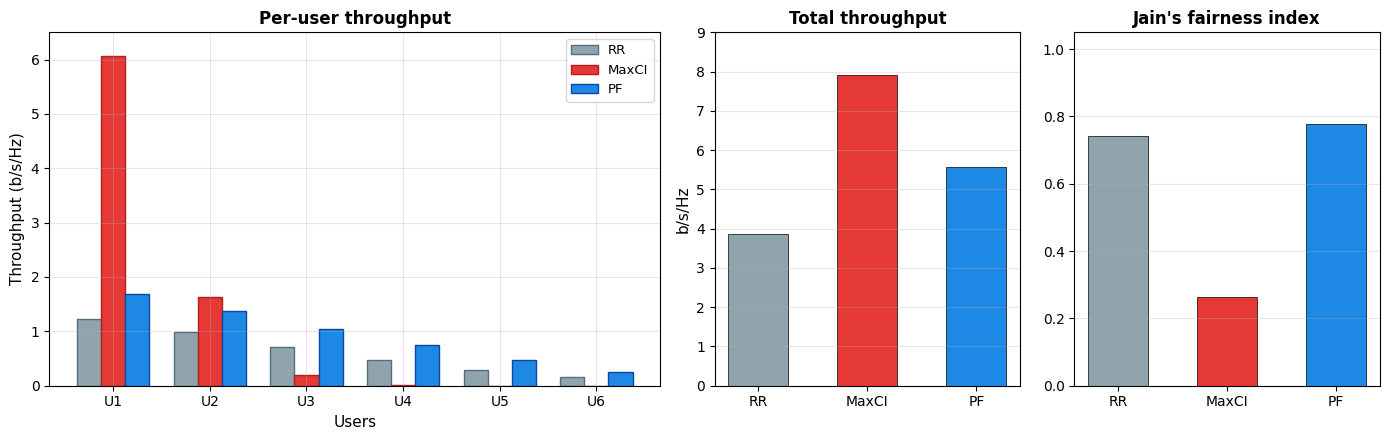


[Saved Graph]: plots/Figure_21_1_OFDMA_Scheduler_Throughput_and_Fairness.png


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs('plots', exist_ok=True)

rng = np.random.default_rng(1)
U, TTI, RB = 6, 2000, 1
mean_snr_db = np.array([25, 20, 15, 10, 5, 0]) # users near -> far
mean_snr = 10**(mean_snr_db / 10)

# Rayleigh fading -> exponential power gain, rate by Shannon (bits/s/Hz)
rate = np.log2(1 + mean_snr * rng.exponential(1.0, (TTI, U)))

def jain(x):
    return x.sum()**2 / (len(x) * (x**2).sum())

def simulate(policy):
    served = np.zeros(U)
    avg = np.ones(U)
    for t in range(TTI):
        if policy == 'RR':
            u = t % U
        elif policy == 'MaxCI':
            u = np.argmax(rate[t])
        else: # Proportional Fair
            u = np.argmax(rate[t] / avg)
        served[u] += rate[t, u]
        inst = np.zeros(U)
        inst[u] = rate[t, u]
        avg = 0.99 * avg + 0.01 * inst
    return served / TTI

print("=" * 60)
print("EXPERIMENT 21: Effect of the OFDMA Downlink Scheduler on User Throughput and Fairness")
print("=" * 60)

results = {}
print(f"{'Scheduler':>10} | " + " ".join(f"U{i+1:>5}" for i in range(U)) + " | Total | Jain")
for p in ('RR', 'MaxCI', 'PF'):
    th = simulate(p)
    results[p] = th
    print(f"{p:>10} | " + " ".join(f"{v:6.3f}" for v in th) + f" | {th.sum():6.3f} | {jain(th):.3f}")

# High-resolution plot matching Figure 21.1 in manual
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.5), gridspec_kw={'width_ratios': [2, 1, 1]})

# Subplot 1: Per-user throughput
users = np.arange(1, U + 1)
w = 0.25
ax1.bar(users - w, results['RR'], width=w, label='RR', color='#90a4ae', edgecolor='#546e7a')
ax1.bar(users, results['MaxCI'], width=w, label='MaxCI', color='#e53935', edgecolor='#b71c1c')
ax1.bar(users + w, results['PF'], width=w, label='PF', color='#1e88e5', edgecolor='#0d47a1')
ax1.set_xlabel('Users', fontsize=11)
ax1.set_ylabel('Throughput (b/s/Hz)', fontsize=11)
ax1.set_title('Per-user throughput', fontsize=12, fontweight='bold')
ax1.set_xticks(users)
ax1.set_xticklabels([f'U{i}' for i in users])
ax1.set_ylim(0, 6.5)
ax1.legend(fontsize=9.5)
ax1.grid(True, alpha=0.3)

# Subplot 2: Total throughput
totals = [results['RR'].sum(), results['MaxCI'].sum(), results['PF'].sum()]
bars2 = ax2.bar(['RR', 'MaxCI', 'PF'], totals, color=['#90a4ae', '#e53935', '#1e88e5'], width=0.55, edgecolor='black', linewidth=0.5)
ax2.set_ylabel('b/s/Hz', fontsize=11)
ax2.set_title('Total throughput', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 9.0)
ax2.grid(True, axis='y', alpha=0.3)

# Subplot 3: Jain's fairness index
fairness = [jain(results['RR']), jain(results['MaxCI']), jain(results['PF'])]
bars3 = ax3.bar(['RR', 'MaxCI', 'PF'], fairness, color=['#90a4ae', '#e53935', '#1e88e5'], width=0.55, edgecolor='black', linewidth=0.5)
ax3.set_ylim(0, 1.05)
ax3.set_title("Jain's fairness index", fontsize=12, fontweight='bold')
ax3.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plot_path = os.path.join('plots', 'Figure_21_1_OFDMA_Scheduler_Throughput_and_Fairness.png')
plt.savefig(plot_path, dpi=300)
plt.show()
print(f"\n[Saved Graph]: {plot_path}")